In [1]:
import numpy as np
import kagglehub
import matplotlib.pyplot as plt
import os

Loading Data

In [2]:
path = kagglehub.dataset_download("msambare/fer2013")

Using Colab cache for faster access to the 'fer2013' dataset.


In [3]:
train_dir = "/kaggle/input/fer2013/train"
val_dir = "/kaggle/input/fer2013/test"

In [4]:
def get_class_counts(directory):
    counts = {}
    if not os.path.exists(directory):
        print(f"Directory {directory} does not exist.")
        return counts
    for class_name in sorted(os.listdir(directory)):
        class_path = os.path.join(directory, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len(os.listdir(class_path))
    return counts

train_counts = get_class_counts(train_dir)
val_counts = get_class_counts(val_dir)

print("Train counts:", train_counts)
print("Validation counts:", val_counts)

Train counts: {'angry': 3995, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}
Validation counts: {'angry': 958, 'disgust': 111, 'fear': 1024, 'happy': 1774, 'neutral': 1233, 'sad': 1247, 'surprise': 831}


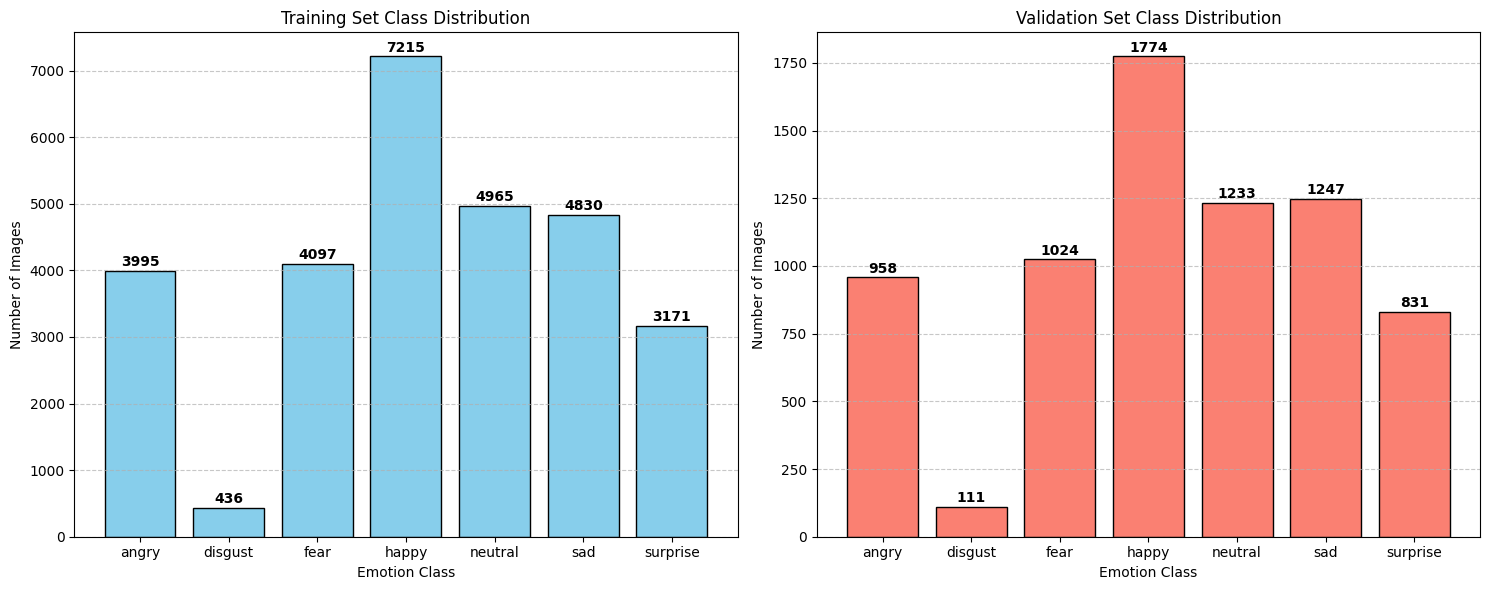

In [5]:
classes = list(train_counts.keys())
train_values = [train_counts[c] for c in classes]
val_values = [val_counts.get(c, 0) for c in classes]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=False)

# Training plot
axes[0].bar(classes, train_values, color='skyblue', edgecolor='black')
axes[0].set_title('Training Set Class Distribution')
axes[0].set_xlabel('Emotion Class')
axes[0].set_ylabel('Number of Images')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(train_values):
    axes[0].text(i, v + (max(train_values)*0.01), str(v), ha='center', fontweight='bold')

# Validation plot
axes[1].bar(classes, val_values, color='salmon', edgecolor='black')
axes[1].set_title('Validation Set Class Distribution')
axes[1].set_xlabel('Emotion Class')
axes[1].set_ylabel('Number of Images')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(val_values):
    axes[1].text(i, v + (max(val_values)*0.01), str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()